In [1]:
%load_ext autoreload
%autoreload 2
import sys
sys.path.append("..")
import numpy as np
import matplotlib.pyplot as plt
from src.logreg import sigmoid, loss, gradients, train, predict_proba

In [2]:
print(sigmoid(np.array([-2, 0, 2])))            # expect [0.119 0.5 0.881]
print(loss(np.array([0.5]), np.array([1])))     # expect 0.693
X = np.array([[1, 0], [1, 1], [0, 1]])
y = np.array([0, 1, 0])
p = np.array([0.2, 0.5, 0.1])
print(gradients(X, y, p))                       # expect ([-0.1, -0.133], -0.067)

[0.11920292 0.5        0.88079708]
0.6931471805599453
(array([-0.1       , -0.13333333]), np.float64(-0.06666666666666667))


In [3]:
data = np.load("../data/features.npz", allow_pickle=True)
X_train, y_train = data["X_train"], data["y_train"]
X_val, y_val = data["X_val"], data["y_val"]
columns = data["columns"]
print(X_train.shape, y_train.mean())

(77181, 261) 0.04652699498581257


In [4]:
rate = y_train.mean()
print("baseline val loss:", loss(np.full(len(y_val), rate), y_val))

baseline val loss: 0.15707470837550863


In [5]:
w, b, hist = train(X_train, y_train, lr=0.5, epochs=1000, X_val=X_val, y_val=y_val)
print("final train:", hist["train"][-1], " final val:", hist["val"][-1])

epoch 0: train loss 0.6931
epoch 100: train loss 0.1776
epoch 200: train loss 0.1743
epoch 300: train loss 0.1728
epoch 400: train loss 0.1719
epoch 500: train loss 0.1712
epoch 600: train loss 0.1706
epoch 700: train loss 0.1701
epoch 800: train loss 0.1698
epoch 900: train loss 0.1694
final train: 0.16913084281753418  final val: 0.1414345559857956


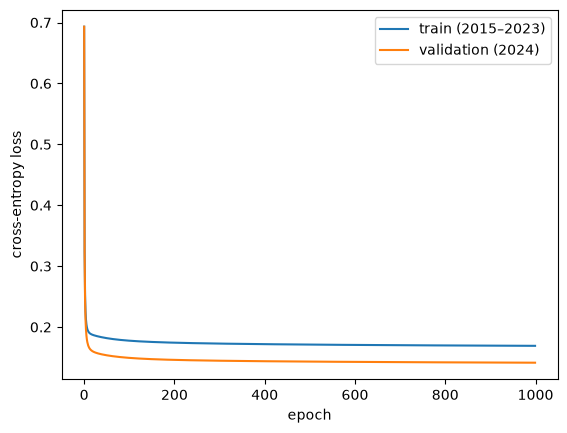

In [6]:
plt.plot(hist["train"], label="train (2015–2023)")
plt.plot(hist["val"], label="validation (2024)")
plt.xlabel("epoch")
plt.ylabel("cross-entropy loss")
plt.legend()
plt.savefig("../plots/loss_logreg.png", dpi=150)
plt.show()